In [1]:
# Load the sys module, which lets us change where Python looks for code
import sys

# Add the parent folder (sales-forecasting) to Python's search path
sys.path.append("..")

# Import your load_raw function from the file src/data.py
from src.data import load_raw

In [2]:
# Load the CSV with your function; "../" goes one folder up from notebooks/ to reach data/
df = load_raw("../data/superstore.csv")

# Show the first 5 rows as a table (the last line of a cell displays automatically)
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
0,1,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600
1,2,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400
2,3,CA-2017-138688,12/06/2017,16/06/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200
3,4,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775
4,5,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680


In [3]:
# Show the size of the table as (number of rows, number of columns)
df.shape

(9800, 18)

In [4]:
# Show every column with its data type and how many values are not missing
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9800 entries, 0 to 9799
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9800 non-null   int64  
 1   Order ID       9800 non-null   str    
 2   Order Date     9800 non-null   str    
 3   Ship Date      9800 non-null   str    
 4   Ship Mode      9800 non-null   str    
 5   Customer ID    9800 non-null   str    
 6   Customer Name  9800 non-null   str    
 7   Segment        9800 non-null   str    
 8   Country        9800 non-null   str    
 9   City           9800 non-null   str    
 10  State          9800 non-null   str    
 11  Postal Code    9789 non-null   float64
 12  Region         9800 non-null   str    
 13  Product ID     9800 non-null   str    
 14  Category       9800 non-null   str    
 15  Sub-Category   9800 non-null   str    
 16  Product Name   9800 non-null   str    
 17  Sales          9800 non-null   float64
dtypes: float64(2), int6

In [5]:
# Load pandas into the notebook and give it the short name "pd"
import pandas as pd

# Convert the text dates to real dates; dayfirst=True because the format is day/month/year
df["Order Date"] = pd.to_datetime(df["Order Date"], dayfirst=True)

In [6]:
# Show the earliest order date in the data
print(df["Order Date"].min())

# Show the latest order date in the data
print(df["Order Date"].max())

2015-01-03 00:00:00
2018-12-30 00:00:00


In [7]:
# Drop the unique Row ID column so identical rows can match, then mark duplicates
dupes = df.drop(columns=["Row ID"]).duplicated()

# Count how many rows are marked as duplicates (True counts as 1)
dupes.sum()

np.int64(1)

In [8]:
# Mark every row that has a twin, keeping both copies (keep=False), ignoring Row ID
both_copies = df.drop(columns=["Row ID"]).duplicated(keep=False)

# Show those rows from the full table so you can compare them side by side
df[both_copies]

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
3405,3406,US-2015-150119,2015-04-23,27/04/2015,Standard Class,LB-16795,Laurel Beltran,Home Office,United States,Columbus,Ohio,43229.0,East,FUR-CH-10002965,Furniture,Chairs,Global Leather Highback Executive Chair with P...,281.372
3406,3407,US-2015-150119,2015-04-23,27/04/2015,Standard Class,LB-16795,Laurel Beltran,Home Office,United States,Columbus,Ohio,43229.0,East,FUR-CH-10002965,Furniture,Chairs,Global Leather Highback Executive Chair with P...,281.372


In [9]:
# Make a list of every column name except Row ID (which is unique and hides duplicates)
cols = [c for c in df.columns if c != "Row ID"]

# Drop rows that repeat in all of those columns, keeping the first copy
df = df.drop_duplicates(subset=cols)

# Show the new size of the table; it should be one row less than before
df.shape

(9799, 18)

In [10]:
# Add up Sales for each sub-category, then sort from biggest to smallest
totals = df.groupby("Sub-Category")["Sales"].sum().sort_values(ascending=False)

# Show the result as a table
totals

Sub-Category
Phones         327782.4480
Chairs         322541.3590
Storage        219343.3920
Tables         202810.6280
Binders        200028.7850
Machines       189238.6310
Accessories    164186.7000
Copiers        146248.0940
Bookcases      113813.1987
Appliances     104618.4030
Furnishings     89212.0180
Paper           76828.3040
Supplies        46420.3080
Art             26705.4100
Envelopes       16128.0460
Labels          12347.7260
Fasteners        3001.9600
Name: Sales, dtype: float64

In [11]:
# Use Order Date as the table's index so pandas can group rows by time
# Take the Sales column, group it into weeks, and add up the sales in each week
weekly_total = df.set_index("Order Date")["Sales"].resample("W").sum()

# Show the first 5 weeks
weekly_total.head()

Order Date
2015-01-04     304.508
2015-01-11    4619.108
2015-01-18    4130.533
2015-01-25    3092.544
2015-02-01    2527.914
Freq: W-SUN, Name: Sales, dtype: float64

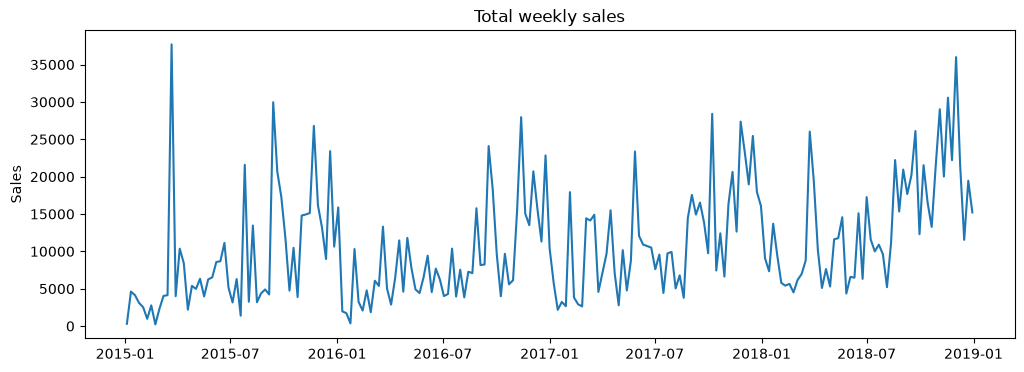

In [12]:
# Load matplotlib's plotting tool and give it the short name "plt"
import matplotlib.pyplot as plt

# Create an empty chart that is 12 inches wide and 4 inches tall
plt.figure(figsize=(12, 4))

# Draw the weekly total sales as a line
plt.plot(weekly_total)

# Add a title so the chart explains itself
plt.title("Total weekly sales")

# Label the vertical axis
plt.ylabel("Sales")

# Display the chart
plt.show()

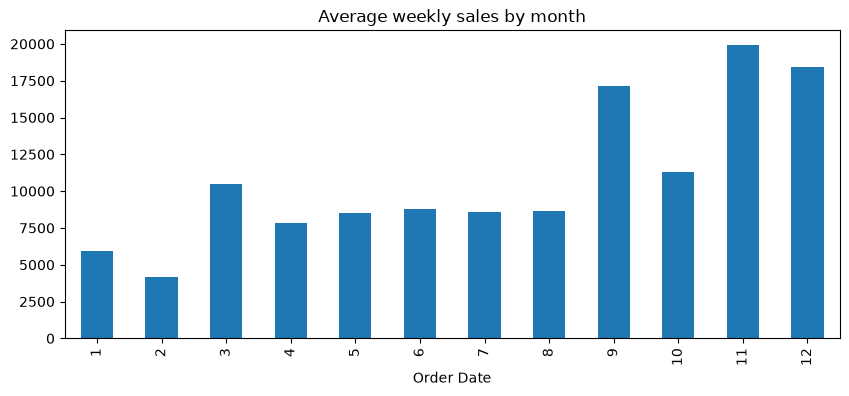

In [13]:
# Group the weekly totals by calendar month (1 = January ... 12 = December)
# and take the average weekly sales for each month
monthly_avg = weekly_total.groupby(weekly_total.index.month).mean()

# Draw the 12 monthly averages as a bar chart
monthly_avg.plot(kind="bar", figsize=(10, 4), title="Average weekly sales by month")

# Display the chart
plt.show()

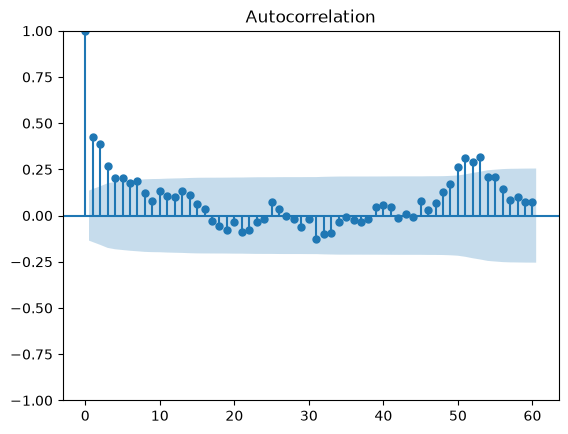

In [14]:
# Load the function that draws an autocorrelation plot
from statsmodels.graphics.tsaplots import plot_acf

# Draw how strongly each week's sales relate to sales 1, 2, 3 ... 60 weeks earlier
plot_acf(weekly_total, lags=60)

# Display the chart
plt.show()

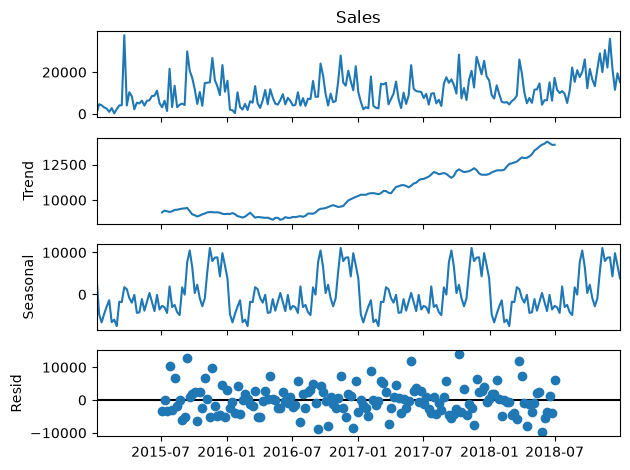

In [15]:
# Load the function that splits a time series into parts
from statsmodels.tsa.seasonal import seasonal_decompose

# Split weekly sales into trend + yearly seasonality + leftover noise (52 weeks = 1 year)
result = seasonal_decompose(weekly_total, model="additive", period=52)

# Draw the four panels: original, trend, seasonal pattern, and residual noise
result.plot()

# Display the chart
plt.show()

In [16]:
# Group sales by sub-category and by week, adding up the sales in each group
weekly_sub = df.groupby(["Sub-Category", pd.Grouper(key="Order Date", freq="W")])["Sales"].sum()

# Turn the sub-categories into columns, so each column is one weekly series
weekly_sub = weekly_sub.unstack(level=0)

# Make sure every week appears (using the weekly_total dates) and fill empty weeks with 0
weekly_sub = weekly_sub.reindex(weekly_total.index).fillna(0)

# Show the size of the table (weeks x sub-categories)
print(weekly_sub.shape)

# Show the first 5 weeks
weekly_sub.head()

(209, 17)


Sub-Category,Accessories,Appliances,Art,Binders,Bookcases,Chairs,Copiers,Envelopes,Fasteners,Furnishings,Labels,Machines,Paper,Phones,Storage,Supplies,Tables
Order Date,,,,,,,,,,,,,,,,,
2015-01-04,0.00,0.000,0.00,3.540,0.000,0.00,0.0,0.00,0.00,0.000,11.784,0.0,16.448,0.00,272.736,0.0,0.0
2015-01-11,31.20,0.000,47.14,620.410,0.000,2573.82,0.0,0.00,31.12,138.608,2.890,0.0,25.980,1147.94,0.000,0.0,0.0
2015-01-18,796.69,64.864,19.90,27.666,395.959,545.94,0.0,62.30,0.00,127.104,30.072,0.0,37.408,124.20,1898.430,0.0,0.0
2015-01-25,0.00,247.716,73.51,148.284,181.470,1067.94,0.0,132.06,0.00,345.570,0.000,0.0,115.504,699.93,80.560,0.0,0.0
2015-02-01,468.90,0.000,36.44,14.608,432.626,0.00,0.0,0.00,0.00,75.240,0.000,0.0,46.680,343.33,777.090,0.0,333.0


In [17]:
# Mark every weekly value that is 0 (True) or not (False), then take the average per column
# The average of True/False is the share of zero weeks (0.0 = never zero, 1.0 = always zero)
zero_share = (weekly_sub == 0).mean()

# Sort from the most zero weeks to the fewest
zero_share = zero_share.sort_values(ascending=False)

# Show the result as a table
zero_share

Sub-Category
Copiers        0.741627
Machines       0.636364
Supplies       0.444976
Bookcases      0.397129
Envelopes      0.382775
Fasteners      0.363636
Tables         0.291866
Labels         0.244019
Appliances     0.167464
Chairs         0.143541
Art            0.081340
Accessories    0.071770
Phones         0.071770
Storage        0.057416
Furnishings    0.028708
Paper          0.019139
Binders        0.004785
dtype: float64

In [18]:
# List the 9 sub-categories we will model
chosen = ["Phones", "Chairs", "Storage", "Binders", "Accessories",
          "Appliances", "Furnishings", "Paper", "Tables"]

# Keep only those columns of the weekly table
weekly_model = weekly_sub[chosen]

# Show the size of the table (should be 209 weeks x 9 sub-categories)
print(weekly_model.shape)

# Show the first 5 weeks
weekly_model.head()

(209, 9)


Sub-Category,Phones,Chairs,Storage,Binders,Accessories,Appliances,Furnishings,Paper,Tables
Order Date,,,,,,,,,
2015-01-04,0.00,0.00,272.736,3.540,0.00,0.000,0.000,16.448,0.0
2015-01-11,1147.94,2573.82,0.000,620.410,31.20,0.000,138.608,25.980,0.0
2015-01-18,124.20,545.94,1898.430,27.666,796.69,64.864,127.104,37.408,0.0
2015-01-25,699.93,1067.94,80.560,148.284,0.00,247.716,345.570,115.504,0.0
2015-02-01,343.33,0.00,777.090,14.608,468.90,0.000,75.240,46.680,333.0


In [21]:
# Load the tool that can reload a module that was already imported
import importlib

# Load your data.py file as a module
import src.data

# Reload it so the notebook uses the new version you just saved
importlib.reload(src.data)

# Import the updated function again
from src.data import load_raw

# Load the data with the new function
df_new = load_raw("../data/superstore.csv")

# Show the size of the table (should be 9799 rows, 18 columns) and the type of Order Date
print(df_new.shape)
print(df_new["Order Date"].dtype)

(9799, 18)
datetime64[us]


In [22]:
# Load the tool that reloads a module that was already imported
import importlib

# Load your data.py file as a module
import src.data

# Reload it so the notebook uses the version with the new function
importlib.reload(src.data)

# Import both functions from your module
from src.data import load_raw, make_weekly_table

# Load and clean the data with your function
df_new = load_raw("../data/superstore.csv")

# Build the weekly table with your new function
weekly_new = make_weekly_table(df_new)

# Show the size of the table (we expect 209 weeks x 17 sub-categories)
print(weekly_new.shape)

# Check that it matches the table you built by hand earlier (this sums the differences)
print((weekly_new - weekly_sub).abs().sum().sum())

(209, 17)
0.0
